In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Titanic-Dataset (4).csv to Titanic-Dataset (4).csv


In [3]:
import io

file_name = next(
    name for name in uploaded
    if name.lower().endswith(".csv")
)

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# Dataset information
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nFirst 5 rows:")
display(df.head())

Number of rows and columns: (891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Statistical summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



First 5 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
# Count missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Remove duplicate rows if any
df = df.drop_duplicates().copy()

# Fill missing values in Age and Fare
if "Age" in df.columns:
    df["Age"] = df["Age"].fillna(df["Age"].median())

if "Fare" in df.columns:
    df["Fare"] = df["Fare"].fillna(df["Fare"].median())

# Fill missing Embarked values
if "Embarked" in df.columns:
    df["Embarked"] = df["Embarked"].fillna(
        df["Embarked"].mode()[0]
    )

print("\nMissing values after basic cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Duplicate rows: 0

Missing values after basic cleaning:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64


Survived
0    549
1    342
Name: count, dtype: int64

Survival percentage:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


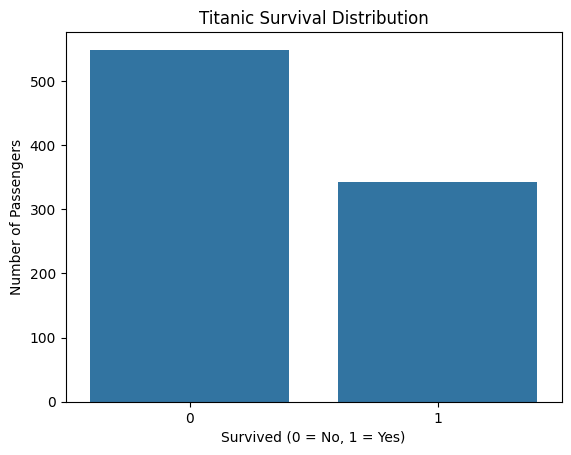

In [6]:
# Count survivors and non-survivors
print(df["Survived"].value_counts())

print("\nSurvival percentage:")
print((df["Survived"].value_counts(normalize=True) * 100).round(2))

# Plot survival distribution
sns.countplot(data=df, x="Survived")
plt.title("Titanic Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

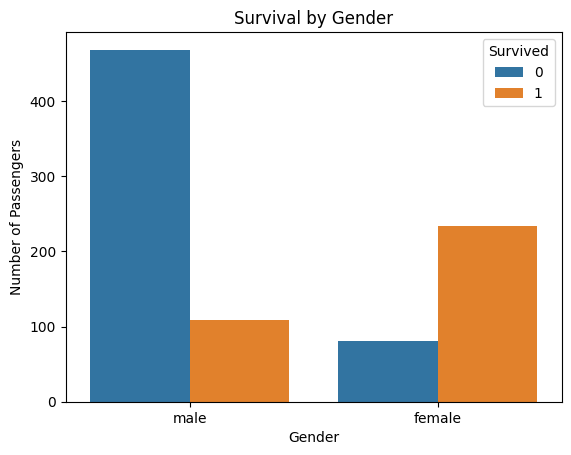

In [7]:
sns.countplot(data=df, x="Sex", hue="Survived")
plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.show()

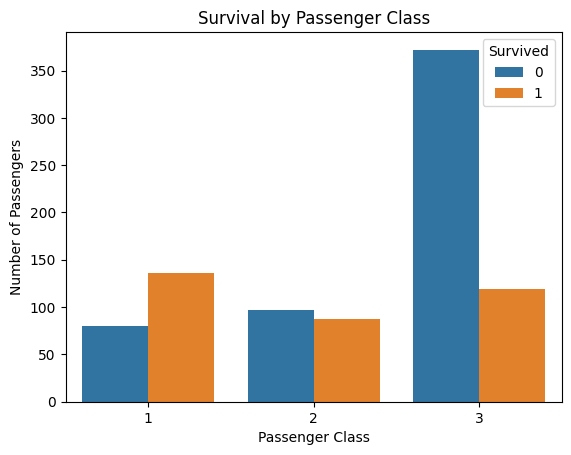

In [8]:
sns.countplot(data=df, x="Pclass", hue="Survived")
plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.show()

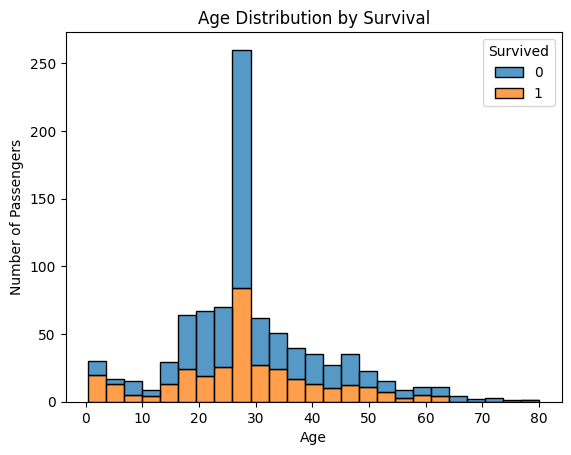

In [9]:
sns.histplot(
    data=df,
    x="Age",
    hue="Survived",
    bins=25,
    multiple="stack"
)
plt.title("Age Distribution by Survival")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()

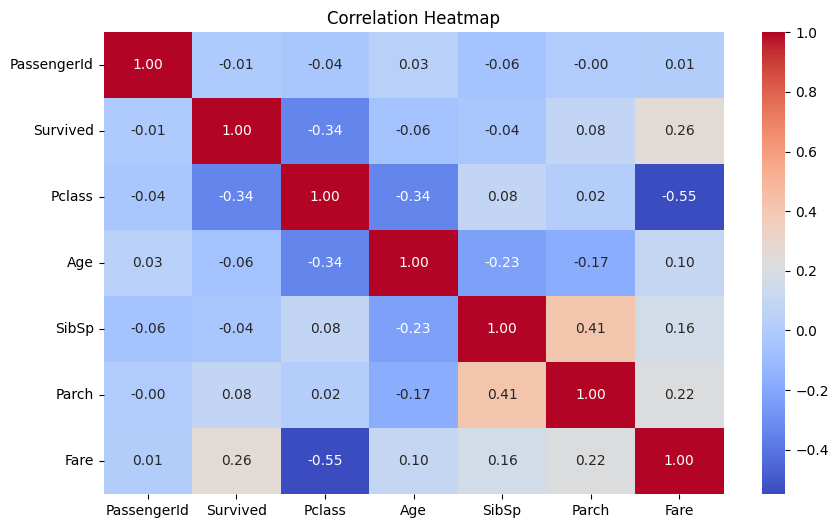

In [10]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

In [11]:
# Features used for prediction
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

# Check that the required columns exist
missing_columns = [
    col for col in features + ["Survived"]
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

X = df[features].copy()
y = df["Survived"].copy()

print("Feature data shape:", X.shape)
print("Target data shape:", y.shape)

display(X.head())

Feature data shape: (891, 7)
Target data shape: (891,)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 712
Testing records: 179


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

numeric_features = [
    "Pclass", "Age", "SibSp", "Parch", "Fare"
]

categorical_features = ["Sex", "Embarked"]

# Process numerical columns
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical columns
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Create the complete model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Machine-learning pipeline created successfully!")

Machine-learning pipeline created successfully!


In [14]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predict outcomes for the test data
y_pred = model.predict(X_test)

# Calculate performance metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nDetailed classification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8045
Precision: 0.7931
Recall: 0.6667
F1 Score: 0.7244

Detailed classification report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



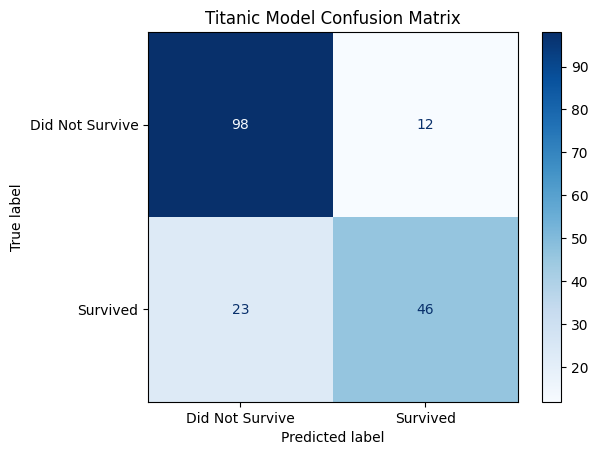

In [16]:
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did Not Survive", "Survived"]
)

display.plot(cmap="Blues")
plt.title("Titanic Model Confusion Matrix")
plt.show()

In [17]:
new_passenger = pd.DataFrame([{
    "Pclass": 3,
    "Sex": "male",
    "Age": 25,
    "SibSp": 0,
    "Parch": 0,
    "Fare": 8.05,
    "Embarked": "S"
}])

prediction = model.predict(new_passenger)[0]
survival_probability = model.predict_proba(new_passenger)[0, 1]

print(
    "Prediction:",
    "Survived" if prediction == 1 else "Did not survive"
)

print(
    "Estimated survival probability:",
    f"{survival_probability:.2%}"
)

Prediction: Did not survive
Estimated survival probability: 9.95%


In [18]:
import joblib

joblib.dump(model, "titanic_survival_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [19]:
report = f"""
CODSOFT DATA SCIENCE INTERNSHIP
PROJECT: TITANIC SURVIVAL PREDICTION

1. OBJECTIVE
Predict whether a Titanic passenger survived
using passenger information and machine learning.

2. DATASET
Dataset file: {file_name}
Number of records after cleaning: {len(df)}
Number of input features: {len(features)}

3. TECHNOLOGY USED
Python, Pandas, NumPy, Matplotlib, Seaborn,
Scikit-learn and Joblib.

4. ALGORITHM
Logistic Regression.

5. DATA PREPROCESSING
Missing numerical values were imputed using
the median. Missing categorical values were
imputed using the most frequent category.
Categorical features were one-hot encoded,
and numerical features were standardized.

6. MODEL EVALUATION
Accuracy: {accuracy_score(y_test, y_pred):.4f}
Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}
Recall: {recall_score(y_test, y_pred, zero_division=0):.4f}
F1 Score: {f1_score(y_test, y_pred, zero_division=0):.4f}

7. CONCLUSION
The Logistic Regression model was trained to
predict passenger survival. Its performance was
evaluated using held-out test data. The results
can help identify patterns associated with
survival in the Titanic dataset.
"""

with open("Titanic_Project_Report.txt", "w", encoding="utf-8") as f:
    f.write(report)

print(report)
print("\nProject report created successfully!")


CODSOFT DATA SCIENCE INTERNSHIP
PROJECT: TITANIC SURVIVAL PREDICTION

1. OBJECTIVE
Predict whether a Titanic passenger survived
using passenger information and machine learning.

2. DATASET
Dataset file: Titanic-Dataset (4).csv
Number of records after cleaning: 891
Number of input features: 7

3. TECHNOLOGY USED
Python, Pandas, NumPy, Matplotlib, Seaborn,
Scikit-learn and Joblib.

4. ALGORITHM
Logistic Regression.

5. DATA PREPROCESSING
Missing numerical values were imputed using
the median. Missing categorical values were
imputed using the most frequent category.
Categorical features were one-hot encoded,
and numerical features were standardized.

6. MODEL EVALUATION
Accuracy: 0.8045
Precision: 0.7931
Recall: 0.6667
F1 Score: 0.7244

7. CONCLUSION
The Logistic Regression model was trained to
predict passenger survival. Its performance was
evaluated using held-out test data. The results
can help identify patterns associated with
survival in the Titanic dataset.


Project report create

In [23]:
from google.colab import files

files.download("titanic_survival_model.pkl")
files.download("Titanic_Project_Report.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>